# From satellite and radar to convection-initiation forecasts
## Read the paper’s results, then explore a real case

**Spatially Explicit Deep Learning Nowcasting of Convection Initiation Using GOES and MRMS**

Marc Crampe · Corey K. Potvin · Jacob T. Carlin · Jonathan J. Gourley · Derek Stratman · Christopher A. Kerr · Said Mejia · Reza Khanbilvardi

[Repository](https://github.com/Marccrampe/goes-mrms-ci-nowcasting) · [Correspondence](mailto:mcrampe@ccny.cuny.edu)

The residual U-Net combines GOES-East infrared observations with MRMS-derived radar features
to forecast CI occurrence in two successive windows. This notebook connects the manuscript’s
aggregate results to the individual objects behind a forecast.

**Two independent demonstrations:**

1. Explore the saved **25 July 2025, 19:00 UTC** case, change verification criteria and inspect objects.
   This is a **TRAIN case**, not an independent estimate of generalization. Only its **0–30-min** forecast is archived.
2. Optionally run the released model on the separate miniature **TEST** sample, producing both forecast windows.

The case explorer needs **CPU only**, no model weights and no raw-data downloads.
It checks the archived files and original classifications before exposing the controls.


## 1 · What is the model trained to predict?

The target representation changes how CI locations enter training. The supplied figure compares
six soft/hard representations; the bottom panels report strict one-to-one TEST CSI after
threshold selection on VALIDATION. The released final model uses **hard +2 model-grid pixels**.

The expanded training target is **not** the observed verification footprint. In the interactive
case below, verification always starts from the canonical, uninflated CI35 birth cores.


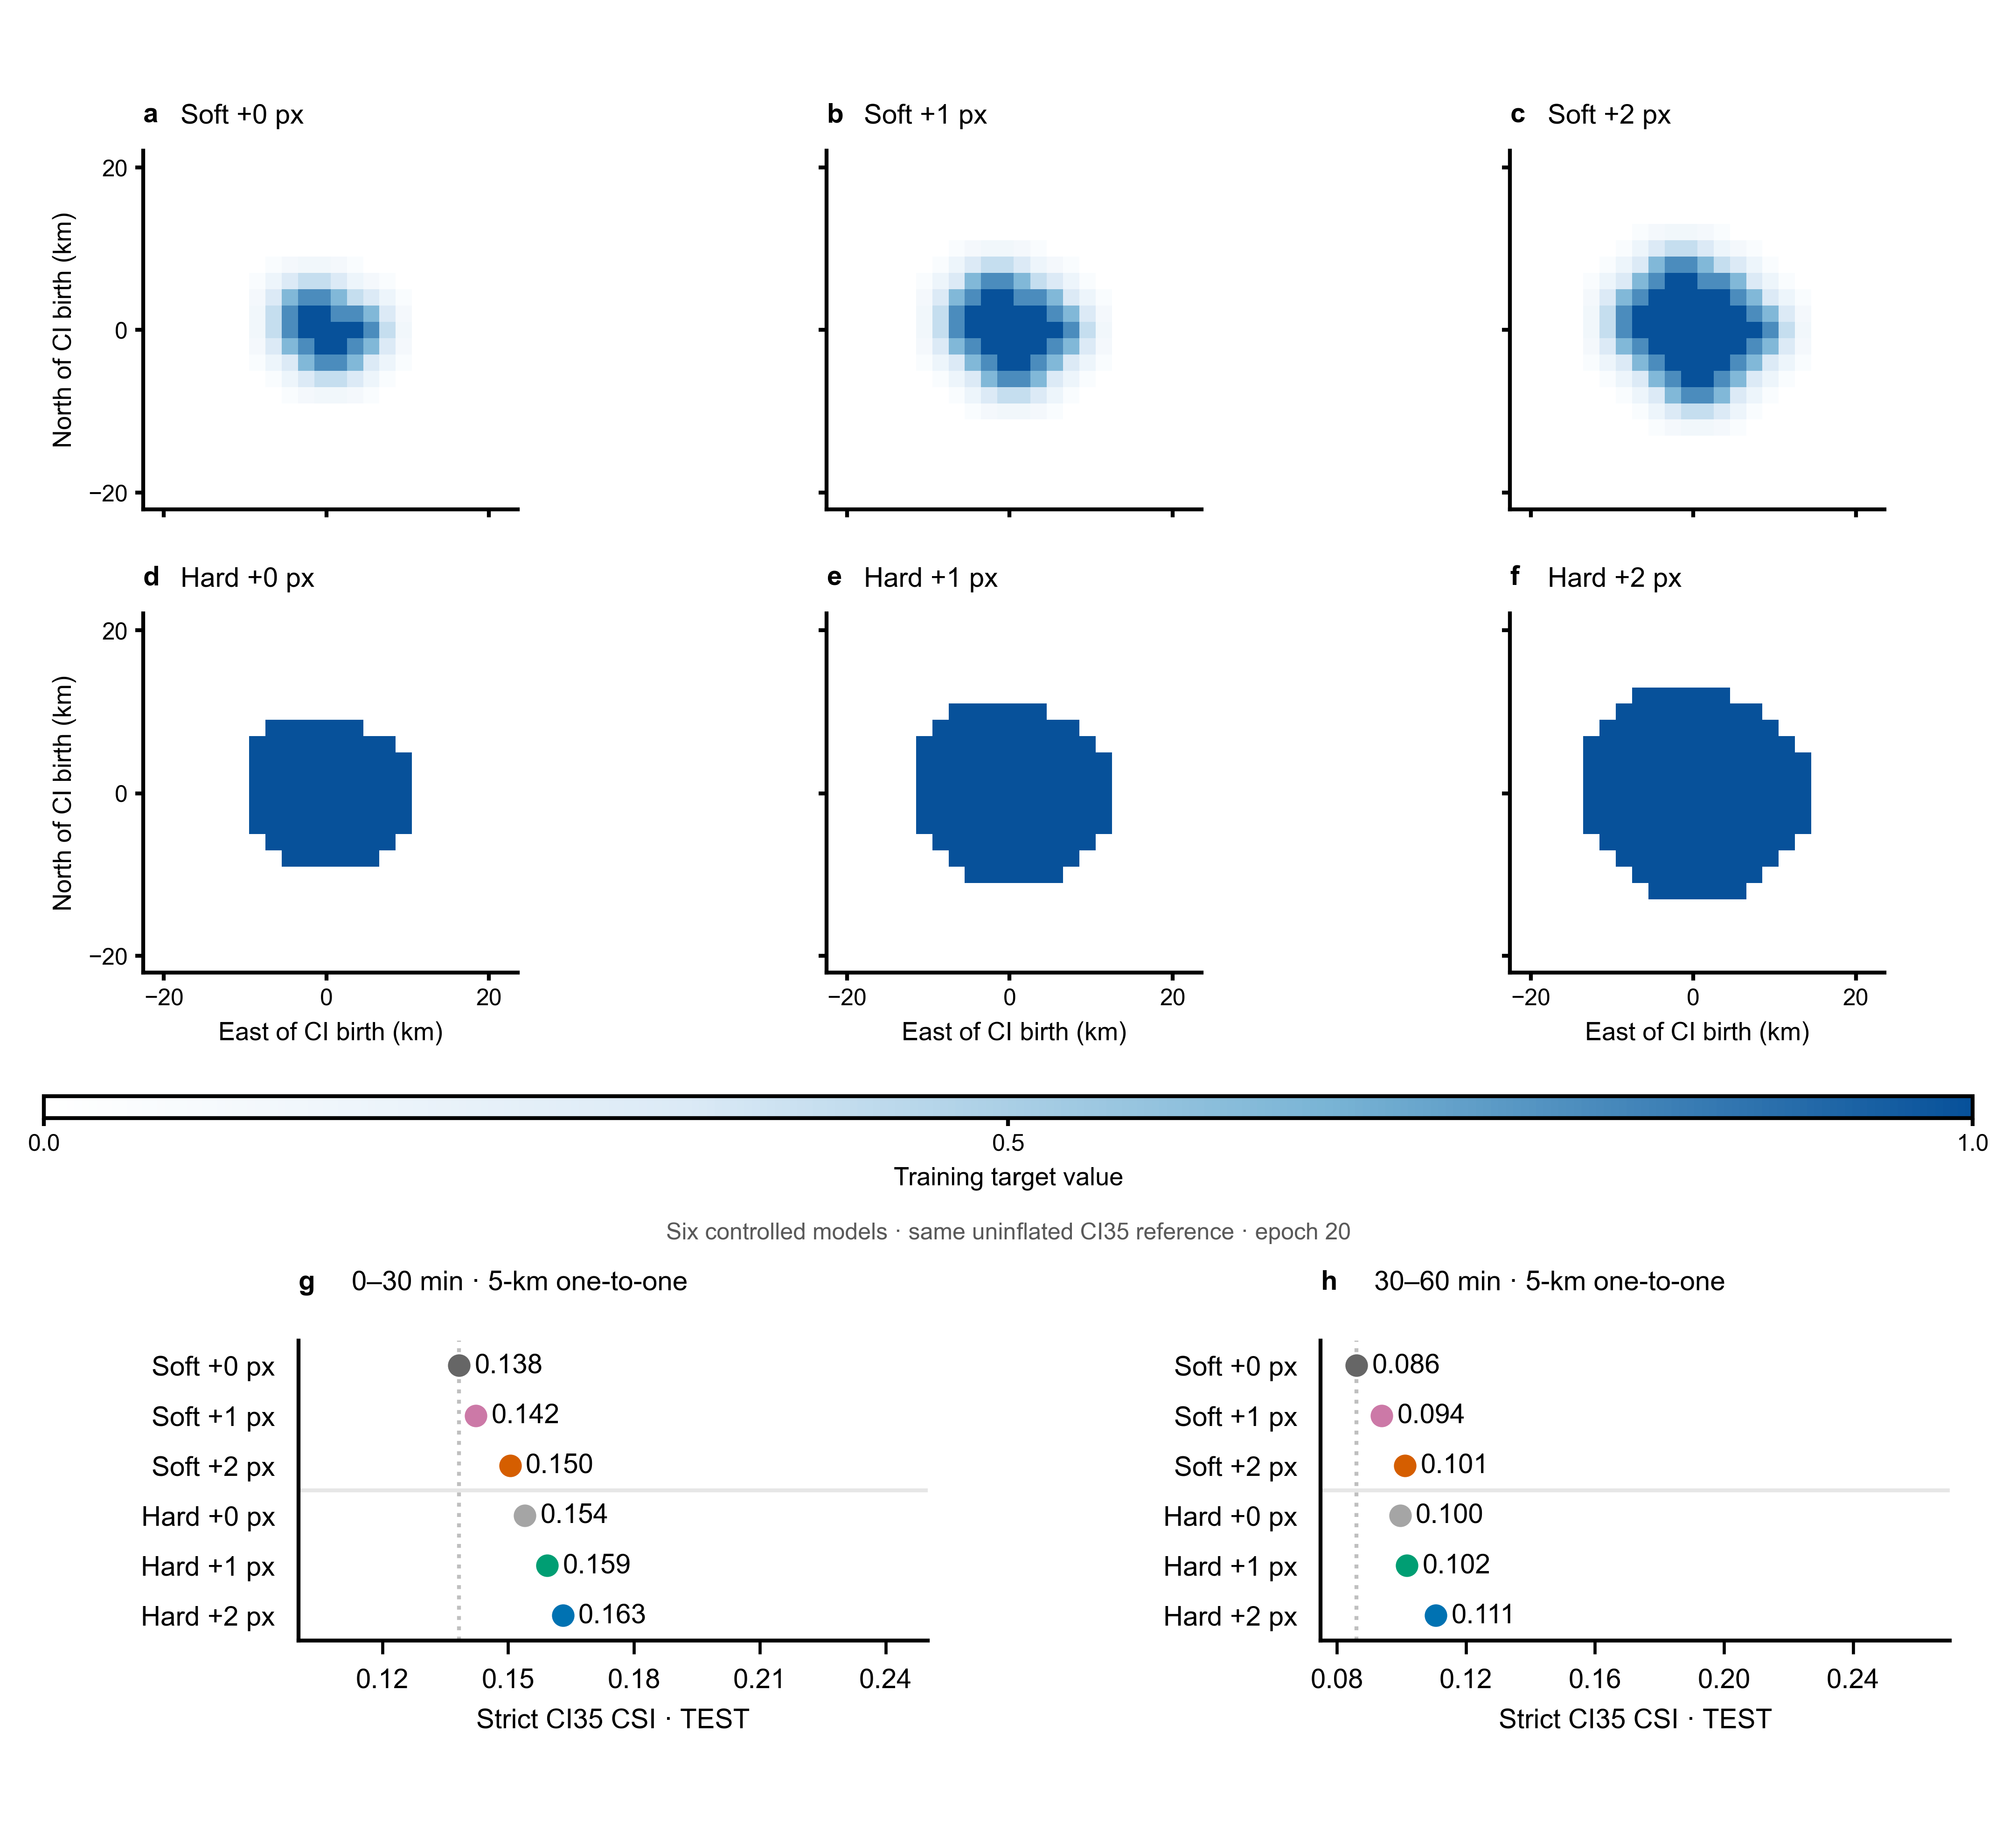


## 2 · What counts as a successful forecast?

Strict CI35 verification and weaker persistent-radar-growth diagnostics answer different questions.
The supplied model-comparison figure illustrates their different scores. Its orange bars use
**≥25 dBZ, 10-min persistence, one native MRMS birth pixel and 15-km association**.

These aggregate manuscript results are included as context. They are **not recomputed from this single case**.
The interactive case uses the archived Fig. 11 diagnostic implementation, whose accounting is
specified below; do not assume that every CSI* figure uses identical reassociation/FN rules.


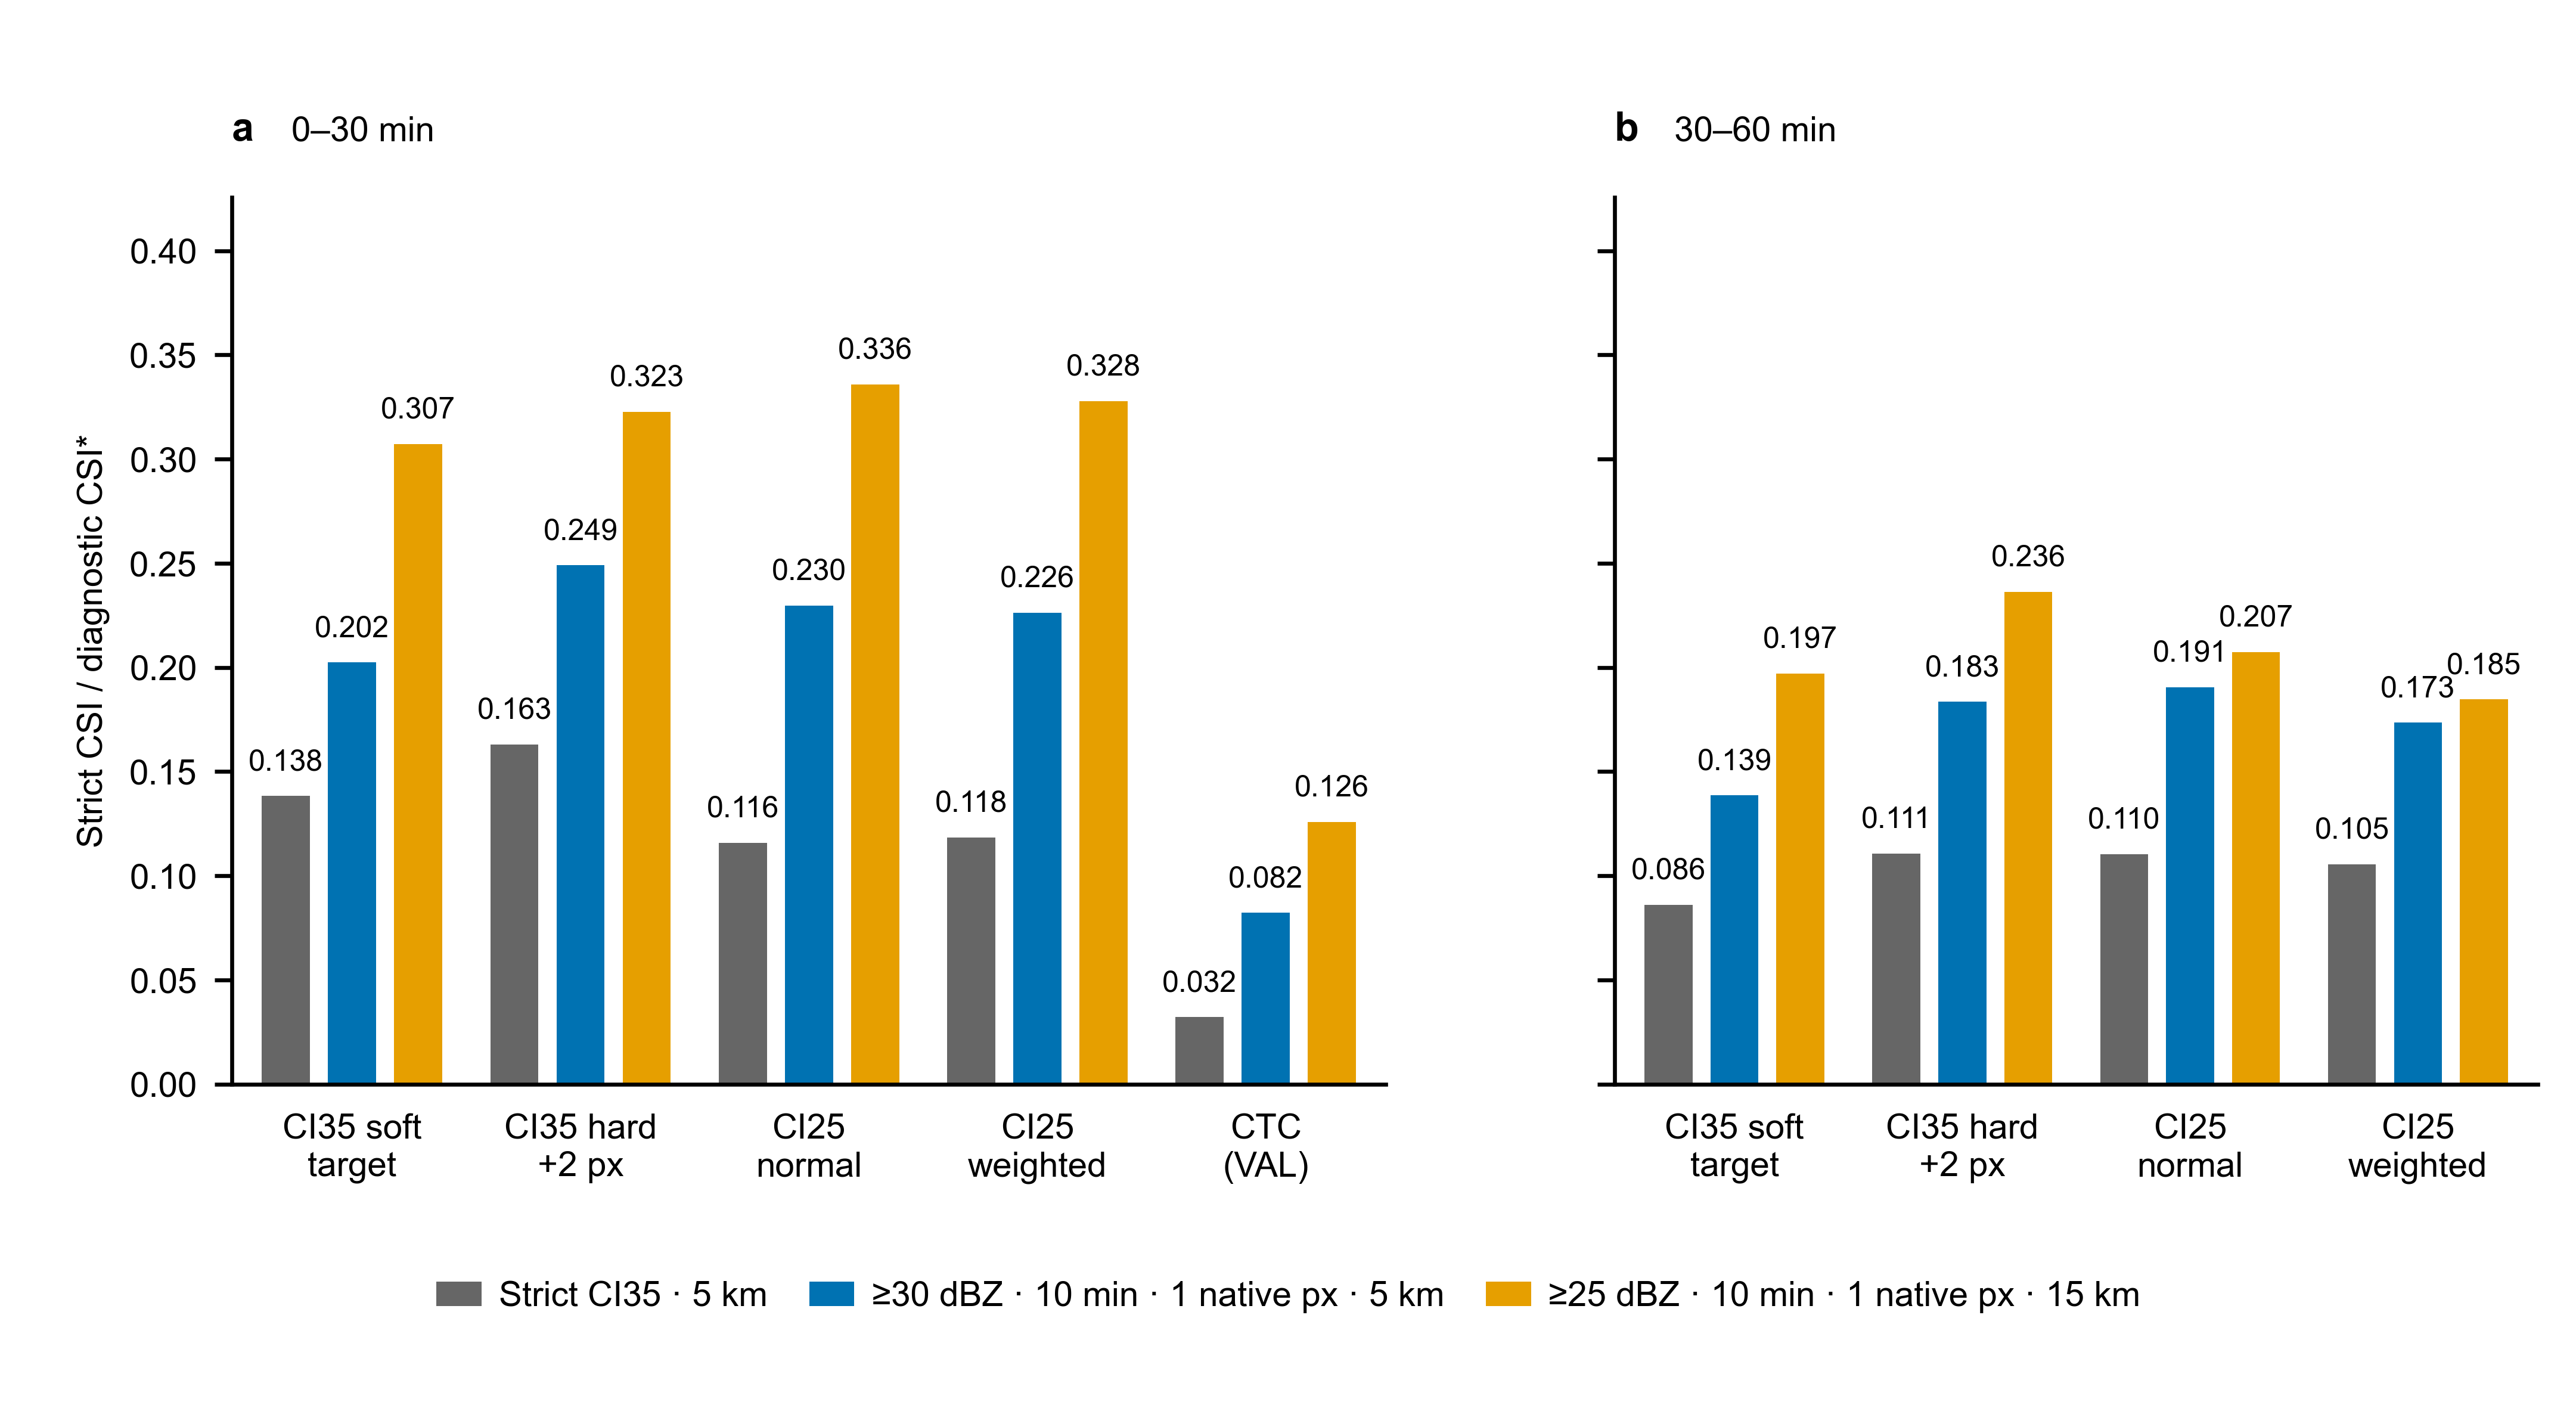


### A separate question: one-to-one matching competition

One forecast object can lie near several observed CI35 initiations, while conventional matching
assigns it to only one. The supplied example shows why additional observations may remain FN.
Recovering those competition FN is a **separate diagnostic** from accepting a forecast on the
basis of weaker radar growth. The controls below do not combine the two operations.


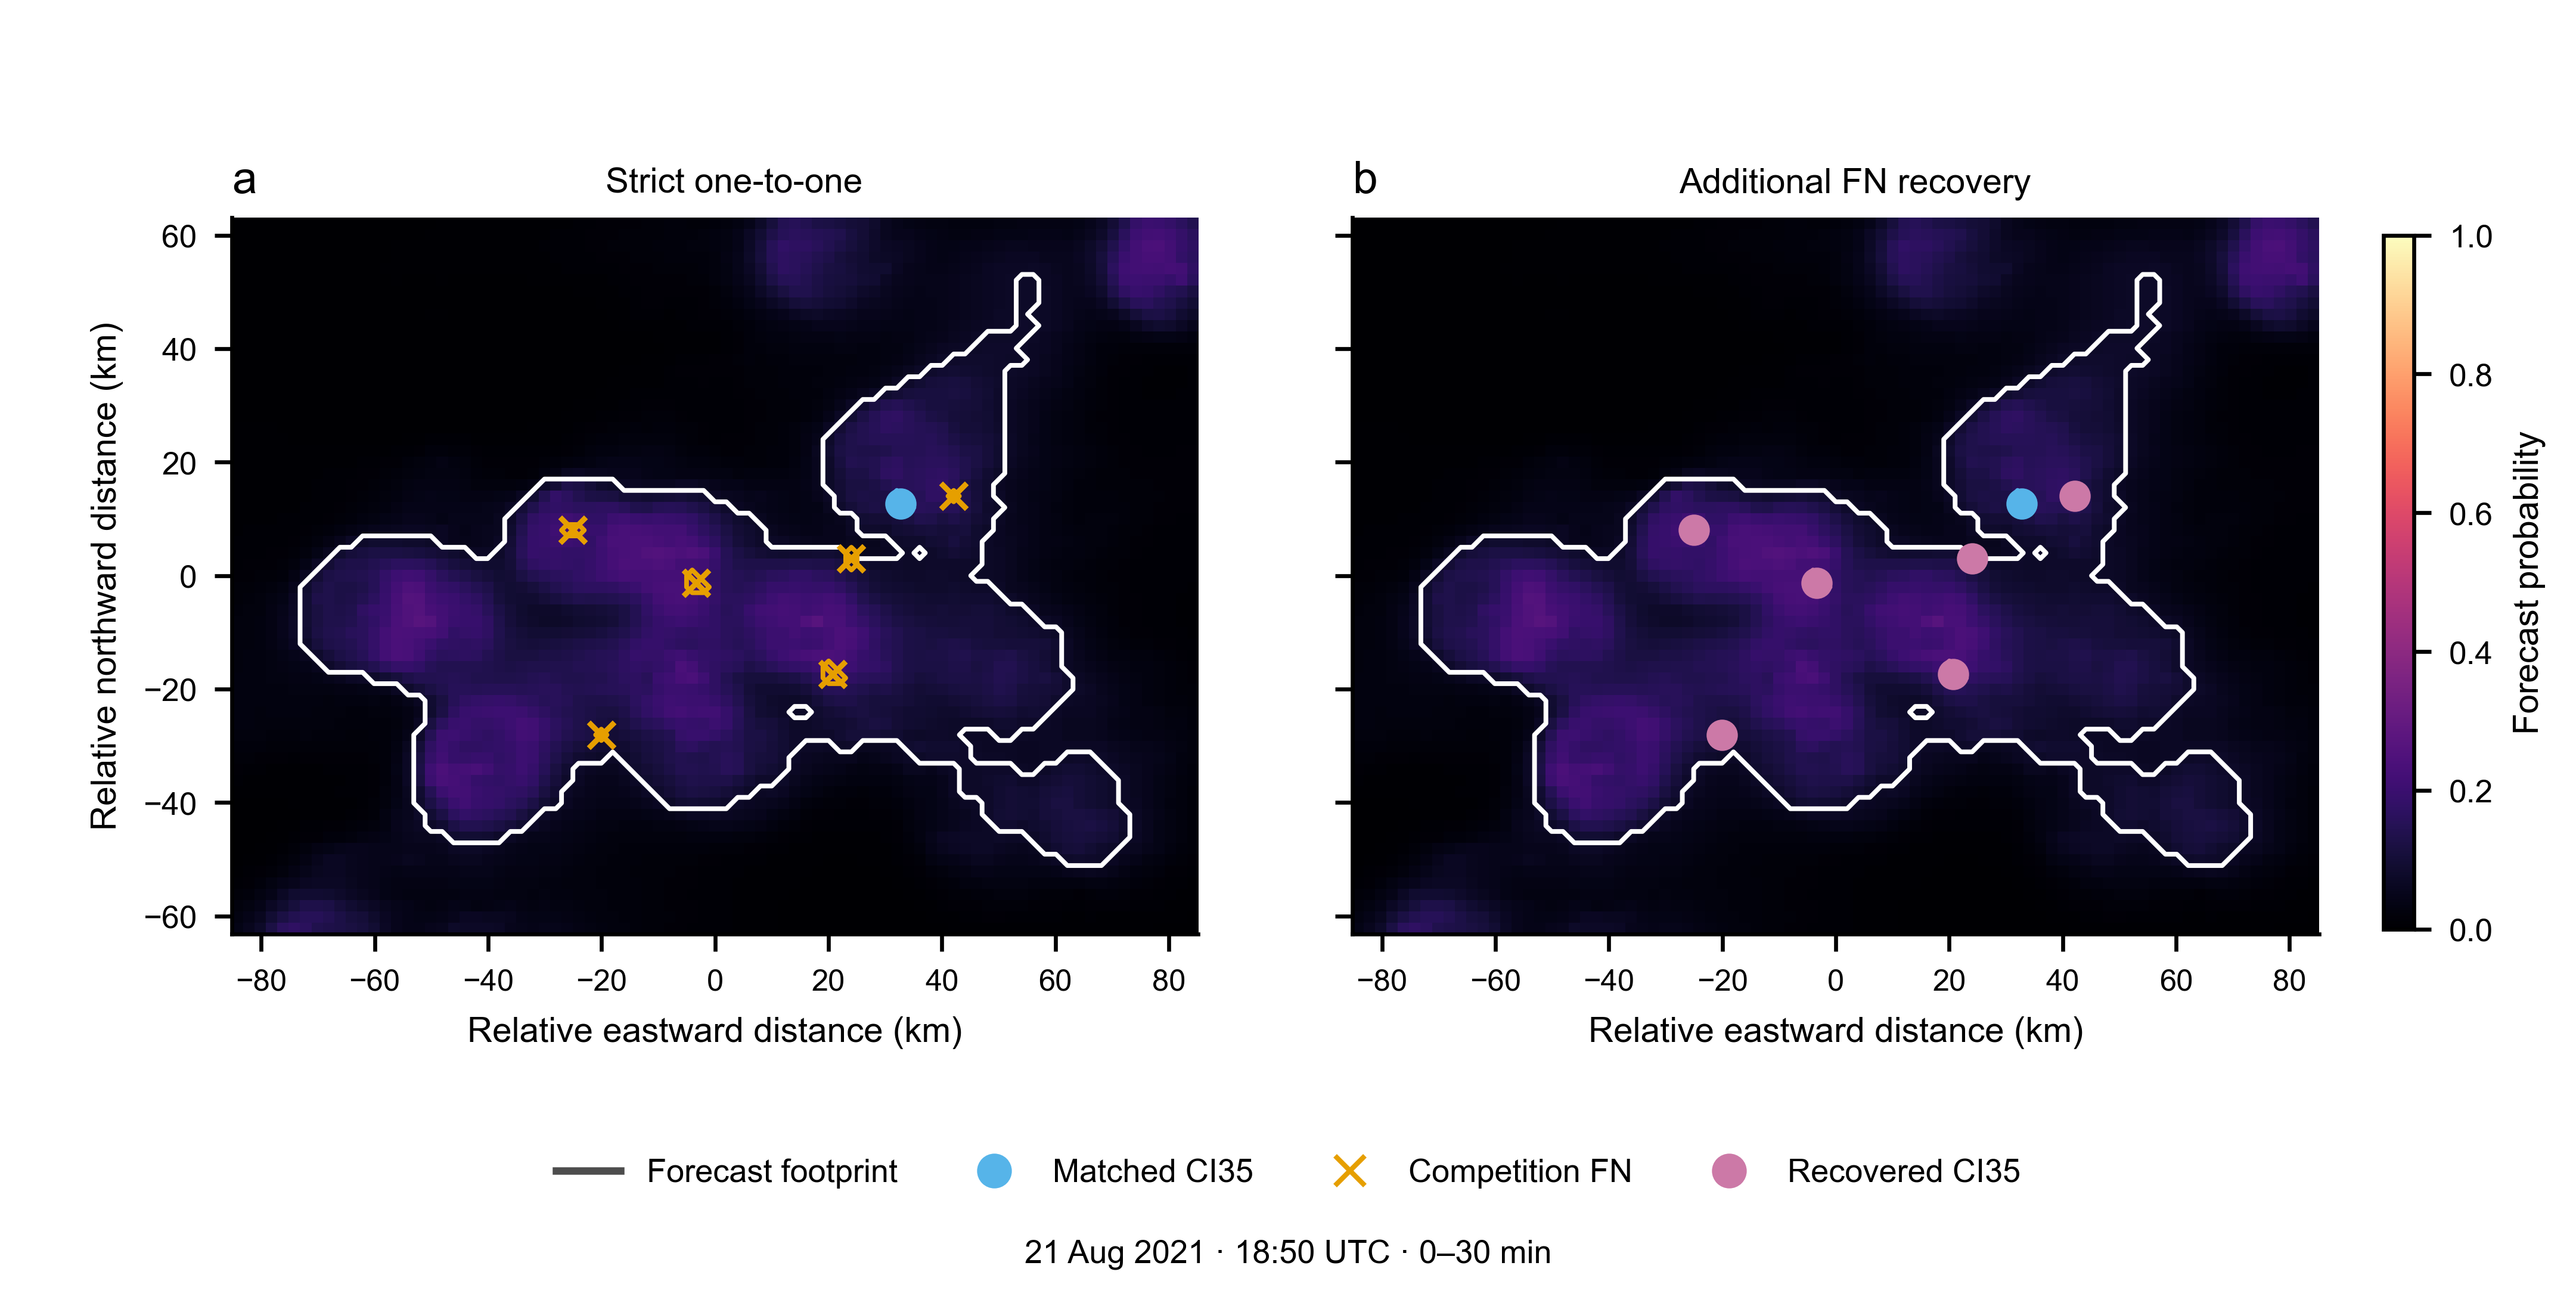


## 3 · Start the case explorer

**Colab:** run the next cell. It uses the repository if available. If these new files have not yet
been uploaded to GitHub, it asks you to upload `Colab_paper_interactive_v1.zip` and installs that
local update in the session. No GitHub write access is needed.

**Local Jupyter:** extract the ZIP and open this notebook from its `notebooks/` directory.


In [ ]:
from pathlib import Path
import sys, subprocess, zipfile

def find_case_root():
    candidates = list(Path.cwd().resolve().parents)
    candidates.insert(0, Path.cwd().resolve())
    candidates += [Path('/content/goes-mrms-ci-nowcasting'), Path('/content/Colab_paper_interactive_v1')]
    return next((p for p in candidates if (p/'tools/object_demo.py').exists()
                 and (p/'examples/fig11_case/manifest.json').exists()), None)

root = find_case_root()
if root is None:
    try:
        from google.colab import files
    except ImportError:
        raise RuntimeError('Extract Colab_paper_interactive_v1.zip and open its notebook locally.')
    repo = Path('/content/goes-mrms-ci-nowcasting')
    if not repo.exists():
        result = subprocess.run(['git', 'clone', '--depth', '1',
            'https://github.com/Marccrampe/goes-mrms-ci-nowcasting.git', str(repo)])
        if result.returncode:
            print('Repository unavailable; the standalone ZIP also works.')
    root = find_case_root()
    if root is None:
        print('Upload Colab_paper_interactive_v1.zip now (code + single-case data).')
        uploaded = files.upload()
        archive = next((Path(n) for n in uploaded if n.endswith('.zip')), None)
        if archive is None:
            raise RuntimeError('No ZIP selected.')
        destination = Path('/content/colab_case_update')
        destination.mkdir(exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            for item in z.infolist():
                p = Path(item.filename)
                if p.is_absolute() or '..' in p.parts or ((item.external_attr >> 16) & 0o170000) == 0o120000:
                    raise RuntimeError('Unsafe ZIP entry')
            z.extractall(destination)
        root = next((p.parent.parent for p in destination.rglob('tools/object_demo.py')), None)
        if root is None:
            raise RuntimeError('The uploaded ZIP is not the case-demo package.')

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(root/'requirements-case-demo.txt')])
sys.path.insert(0, str(root/'tools'))
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    pass
print('Case-demo files:', root)


### Verify the reference result first

The case contains full-domain probabilities, canonical CI35 core indices, original decisions,
projected radar scans and native-radar lineage profiles. No training target is used as truth.

At the original raw threshold **0.05**, strict **5-km** matching and a minimum **2 forecast pixels**,
the reference is **TP 7 / FP 10 / FN 9**. The original ≥25-dBZ/P5/15-km diagnostic accepts
**8 additional forecasts** and leaves **2 unmatched forecasts**.

The exported config’s diagnostic description disagrees with the saved case: the config says
30 dBZ/P10, whereas the saved decisions say **25 dBZ/P5**. The notebook reproduces and validates
the **saved decisions**, then labels every exploratory setting explicitly.


In [ ]:
from object_demo import CaseStudy, launch, radar_player
from IPython.display import display
case = CaseStudy(root/'examples/fig11_case')
display(case.evaluate()['metrics'].round(6))
print('PASS: archived hashes, original TP/FP/FN, matched object IDs and growth associations reproduced.')
print('Period:', case.score['period_id'], '| split:', case.score['split'], '| forecast: (0,30] min')


## 4 · Change the criteria, then inspect the objects

- **Probability threshold** changes the connected forecast objects; these changes are exploratory.
- **Persistence** filters the observed ≥25-dBZ lineages using their saved temporal profiles.
- **Growth radius** controls association for the weaker-growth diagnostic. Strict CI35 remains at **5 km**.
- **Native birth area** filters radar candidates; forecast objects still require two model-grid pixels.
- **Display extent** changes only the view. Matching and counts always use the full **212 × 230** domain.

**Green:** accepted forecasts. **Red:** unmatched forecasts. **Blue circles:** strict matched CI35.
**Blue crosses:** strict CI35 FN, including competition FN. **Orange circles:** accepted ≥25-dBZ growth candidates.

The original growth rule additionally requires novelty, at least three contiguous scans,
intensity or native-area growth, valid coverage and topology checks. Persistence alone is insufficient.
Only ≥25-dBZ candidate lineages are archived, so no unsupported 30/35-dBZ selector is offered.

Select **Show forecast IDs**, then inspect an object below the maps. A fixed-forecast-footprint
radar maximum is contextual information; it does not by itself establish a new CI35 birth.


In [ ]:
state = launch(case)


## 5 · Follow the radar through the forecast window

Play or step through every available radar scan in (19:00, 19:30] UTC. The optional white
outlines remain the **original p = 0.05 forecast objects**, independently of the exploratory controls above.
The radar imagery is projected with the original maximum-reflectivity mapper, not linear interpolation.


In [ ]:
radar_player(case)


## 6 · Read the accounting

Let strict counts be TP, FP and FN, and let G be the number of eligible strict-FP forecasts
accepted by the radar-growth diagnostic. Strict TP, strict FN and forecast geometry are retained:

| Quantity | Strict | Fig. 11 growth diagnostic |
|---|---|---|
| Accepted forecasts | TP | TP + G |
| Unmatched forecasts | FP | FP − G |
| Strict observed FN | FN | FN |
| CSI / CSI* | TP / (TP + FP + FN) | (TP + G) / (TP + FP + FN) |
| POD / POD* | TP / (TP + FN) | (TP + G) / (TP + G + FN) |
| FAR / FAR* | FP / (TP + FP) | (FP − G) / (TP + FP) |

Duplicate forecasts near strict observations are excluded from growth promotion. Matching is one-to-one
between eligible growth candidates and eligible forecasts. **Competition FN are not recovered here.**
The diagnostic scores are not conventional CI35 event scores or the separate association-based CSI.

At the original settings, the counts yield CSI = 7/26 and CSI* = 15/26. The agreement with the
saved figure is a reproducibility check, not evidence of independent predictive skill for this TRAIN case.

Use **Export current tables + settings** above to save the current metrics, object ledger and protocol settings.


## 7 · Optional: run the released neural network

The case explorer above uses the original full-domain saved forecast. It does not run inference.
The repository’s separate miniature TEST sample can exercise the released checkpoint and produce
both 0–30- and 30–60-min outputs. This optional section downloads ~309 MiB of weights and requires
the complete repository; it does not replace the saved Figure 11 forecast.


In [ ]:
RUN_MODEL_DEMO = False  # Change to True to run the separate miniature TEST inference.
if RUN_MODEL_DEMO:
    repo = next((p for p in [root, Path('/content/goes-mrms-ci-nowcasting')]
                 if (p/'models/inference.py').exists() and (p/'tools/demo_support.py').exists()), None)
    if repo is None:
        raise RuntimeError('This optional section needs the complete GitHub repository.')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(repo/'requirements-demo.txt')])
    sys.path.insert(0, str(repo/'tools'))
    from demo_support import run_inference, show_demo
    run_inference(repo)
    import ipywidgets as widgets
    display(widgets.interactive(show_demo, root=widgets.fixed(repo),
        window=widgets.Dropdown(options=[('0–30 min',0), ('30–60 min',1)], description='Window'),
        history=widgets.Dropdown(options=[('−30 min',0), ('−20 min',1), ('−10 min',2), ('T0',3)], value=3),
        display_max=widgets.Dropdown(options=[.1,.25,.5,1.],value=.5,description='Colour max')))
else:
    print('Optional inference skipped. The full case explorer needs no checkpoint or GPU.')


### Provenance and limits

- Source/export checksums: `examples/fig11_case/manifest.json`.
- Numerical functions and source locations: `tools/object_kernel_sources.json`.
- Original scores, associations and object ledger: `examples/fig11_case/verification/`.
- Missing assets and available intervals: `examples/fig11_case/MISSING.md` and `README.md`.
- The supplementary competition image is a **different case**, shown only to explain that mechanism.
- Images above are author-supplied manuscript figures; their aggregate results are static context.
- Only one forecast window and only ≥25-dBZ candidate tracks are supplied for the interactive case.
- The raw output is not isotonic calibrated. The saved case has C13 history, not all seven ABI bands.

**Correspondence:** Marc Crampe · mcrampe@ccny.cuny.edu
